<a href="https://colab.research.google.com/github/Tavonga03/ML/blob/main/praktikum_pca_lda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Praktikum Reduksi Dimensi — PCA dan LDA
Pembelajaran Mesin — Informatika, Universitas Sanata Dharma

Lanjutan dari praktikum Cluster Analysis. Dataset yang dipakai SAMA, sehingga
mahasiswa sudah mengenal datanya dan bisa fokus pada konsep reduksi dimensi.

* BAGIAN A — Dry Bean (13.611 biji, 16 fitur bentuk, 7 varietas).
  Pada praktikum sebelumnya terlihat 16 fitur ini sangat redundan (21 pasangan
  berkorelasi > 0,9). Pertanyaannya sekarang: berapa dimensi yang sebenarnya
  dibutuhkan, dan apa bedanya mereduksi dimensi TANPA label (PCA) dan DENGAN
  label (LDA)?
* BAGIAN B — Kartu Kredit (8.950 nasabah, 17 fitur, tanpa label).
  PCA bisa langsung dipakai. LDA tidak bisa, karena LDA butuh label kelas.
  Kita akan "meminjam" label dari hasil K-Means untuk menjelaskan segmen.

Ringkasnya:
  PCA : unsupervised, mencari arah dengan VARIANS terbesar.
  LDA : supervised, mencari arah yang paling MEMISAHKAN KELAS
        (rasio varians antar-kelas / dalam-kelas). Maksimal (jumlah kelas − 1) komponen.

Kebutuhan: numpy, pandas, matplotlib, seaborn, scikit-learn.

In [32]:
# =============================================================================
# 0. IMPORT AND CONFIGURATION
# =============================================================================
import os  # Access operating system functionalities like directory creation
import time  # Measure code execution time
import warnings  # Manage system/library warnings

import matplotlib.pyplot as plt  # Core library for creating visualizations and plots
import numpy as np  # Library for numerical computing and array manipulation
import pandas as pd  # Library for data analysis and dataframe manipulation
import seaborn as sns  # Advanced data visualization library built on top of matplotlib
from sklearn.cluster import KMeans  # K-Means clustering algorithm
from sklearn.decomposition import PCA  # Principal Component Analysis for unsupervised dimensionality reduction
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA  # Linear Discriminant Analysis for supervised dimensionality reduction
from sklearn.linear_model import LogisticRegression  # Logistic Regression classification algorithm
from sklearn.metrics import adjusted_rand_score, classification_report  # Metrics for evaluating clustering (ARI) and classification
from sklearn.model_selection import train_test_split  # Split dataset into training and testing sets
from sklearn.neighbors import KNeighborsClassifier  # K-Nearest Neighbors classification algorithm
from sklearn.pipeline import make_pipeline  # Build sequential pipelines for consistent data processing
from sklearn.preprocessing import StandardScaler  # Standardize features by scaling to zero mean and unit variance

warnings.filterwarnings("ignore")  # Ignore warning messages to keep the output clean
sns.set_theme(style="whitegrid")  # Set the default seaborn plot style to white grid
RANDOM_STATE = 42  # Define a constant random seed for reproducibility
OUT_DIR = "output_pca_lda"  # Name of the directory to save output plots and files
os.makedirs(OUT_DIR, exist_ok=True)  # Create the output directory if it does not already exist


def simpan(fig, nama):
    """Save figure to the output folder and display it."""
    # Build the full file path and save the figure with 150 DPI resolution
    fig.savefig(os.path.join(OUT_DIR, nama), dpi=150, bbox_inches="tight")
    plt.show()  # Display the figure in the notebook output

---
# BAGIAN A — Dry Bean
## A.1 Data dan pembagian train/test
LDA adalah metode SUPERVISED. Agar evaluasinya jujur, PCA, LDA, dan scaler
hanya boleh "belajar" dari data latih. Data uji dipakai untuk mengukur hasil.

In [33]:
# Read the dry bean dataset, remove duplicates, and reset the index in-place
bean = pd.read_csv("dataset_dry_bean.csv").drop_duplicates().reset_index(drop=True)
# Filter all feature columns by excluding the target label column 'Class'
FITUR = [c for c in bean.columns if c != "Class"]
# Separate the feature variables (X) and target class labels (y)
X_all= bean[FITUR] #making x_all to be fitur
y_all = bean["Class"] # making y target class
# Print the total shape of the dataset and count unique classes
print("Ukuran data:", bean.shape, "| jumlah kelas:", y_all.nunique())

# Split data into stratified training (70%) and test (30%) sets for fair evaluation
X_tr, X_te, y_tr, y_te = train_test_split(X_all, y_all, test_size=0.3,
                                          stratify=y_all, random_state=RANDOM_STATE)
# Instantiate and fit standard scaler only on the training features
scaler = StandardScaler().fit(X_tr)
# Apply the fitted scaler to transform both training and test features
Z_tr, Z_te = scaler.transform(X_tr), scaler.transform(X_te)
# Output the resulting dimensions of train and test matrices
print("Train:", Z_tr.shape, "| Test:", Z_te.shape)

# Get an alphabetically sorted list of all unique target class labels
KELAS = sorted(y_all.unique())
# Map each unique class to a distinct color from the tab10 categorical palette
PALET = dict(zip(KELAS, sns.color_palette("tab10", len(KELAS))))

Ukuran data: (13543, 17) | jumlah kelas: 7
Train: (9480, 16) | Test: (4063, 16)


## A.2 PCA dari nol (untuk memahami apa yang terjadi di dalam PCA)
PCA = eigen-dekomposisi matriks kovarians data yang sudah dipusatkan.
Eigenvector = arah komponen utama; eigenvalue = varians pada arah itu.

In [34]:
# Calculate the 16 x 16 covariance matrix of the scaled training data (features as columns)
C = np.cov(Z_tr, rowvar=False)
# Compute eigenvalues and eigenvectors for the symmetric covariance matrix
eigval, eigvec = np.linalg.eigh(C)
# Sort the eigenvalues (and corresponding eigenvectors) in descending order of variance
urut = np.argsort(eigval)[::-1]
# Reorder both eigenvalues and eigenvectors based on the sorted indices
eigval, eigvec = eigval[urut], eigvec[:, urut]
# Compute the proportion of variance explained by each principal component manually
rasio_manual = eigval / eigval.sum()

# Instantiate and fit a full PCA model using scikit-learn on the scaled training features
pca_full = PCA().fit(Z_tr)
# Print the variance ratios of the first 5 components calculated manually
print("Rasio varians (manual)  :", rasio_manual[:5].round(4))
# Print the variance ratios of the first 5 components calculated by scikit-learn
print("Rasio varians (sklearn) :", pca_full.explained_variance_ratio_[:5].round(4))
# Verify if the absolute values of eigenvectors match between manual calculations and scikit-learn
print("Komponen sama (|nilai|)?:",
      np.allclose(np.abs(eigvec[:, :5].T), np.abs(pca_full.components_[:5]), atol=1e-6))

Rasio varians (manual)  : [0.5554 0.2637 0.0803 0.0513 0.027 ]
Rasio varians (sklearn) : [0.5554 0.2637 0.0803 0.0513 0.027 ]
Komponen sama (|nilai|)?: True


## A.3 Berapa komponen PCA yang dibutuhkan?

Komponen untuk 90% varians: 4 | 95%: 4 | 99%: 7
Kriteria Kaiser (eigenvalue > 1): 3 komponen


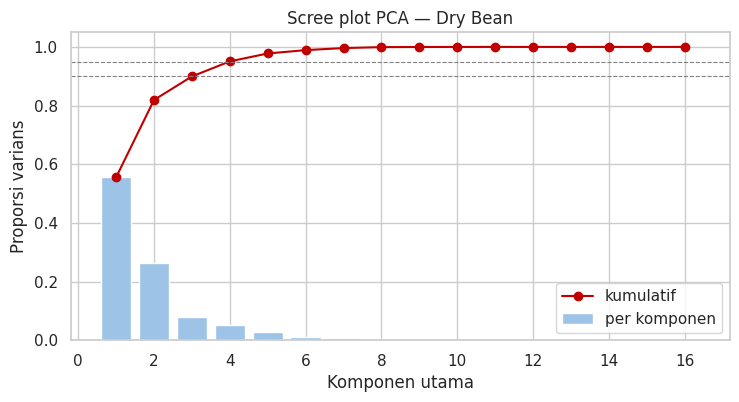

In [35]:
# Extract the explained variance ratio of each principal component from scikit-learn's PCA
evr = pca_full.explained_variance_ratio_
# Compute the cumulative sum of explained variance ratio to find the overall variance retained
kum = np.cumsum(evr)
# Identify the minimum number of components needed to retain 90%, 95%, and 99% variance
n90, n95, n99 = [int(np.argmax(kum >= t) + 1) for t in (0.90, 0.95, 0.99)]
# Print the component thresholds required for 90%, 95%, and 99% cumulative variance
print(f"Komponen untuk 90% varians: {n90} | 95%: {n95} | 99%: {n99}")
# Calculate and print how many components satisfy the Kaiser criterion (eigenvalue > 1)
print("Kriteria Kaiser (eigenvalue > 1):", int((pca_full.explained_variance_ > 1).sum()), "komponen")

# Initialize a single subplot with custom figure size
fig, ax = plt.subplots(figsize=(8.5, 4))
# Draw a bar chart showing the individual variance explained by each principal component
ax.bar(range(1, len(evr) + 1), evr, color="#9dc3e6", label="per komponen")
# Draw a line plot representing the cumulative explained variance across components
ax.plot(range(1, len(evr) + 1), kum, "o-", color="#c00000", label="kumulatif")
# Add horizontal dashed lines marking the 90% and 95% variance thresholds
for t in (0.90, 0.95):
    ax.axhline(t, ls="--", color="grey", lw=0.8)
# Set labels for the axes, add a title, and define plot boundaries
ax.set(xlabel="Komponen utama", ylabel="Proporsi varians", title="Scree plot PCA — Dry Bean")
# Add the legend to distinguish individual and cumulative plots
ax.legend()
# Save the generated scree plot figure to the specified output path
simpan(fig, "A1_scree_pca.png")

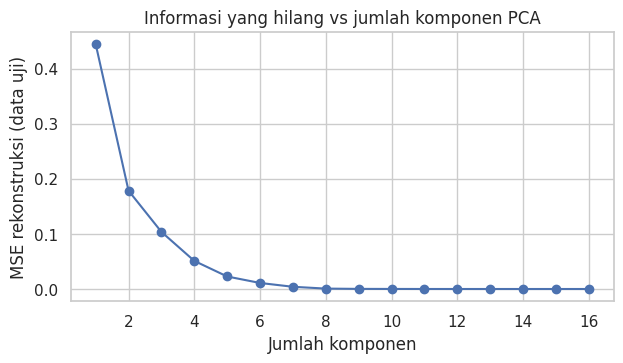

[4.451e-01 1.786e-01 1.038e-01 5.100e-02 2.270e-02 1.090e-02 4.000e-03
 7.000e-04 2.000e-04 1.000e-04 0.000e+00 0.000e+00 0.000e+00 0.000e+00
 0.000e+00 0.000e+00]
MSE at k = 4: 0.051


In [36]:
# Initialize an empty list to store reconstruction error values for each component count
err = []
# Loop through different numbers of principal components from 1 up to the total number of features
for k in range(1, len(FITUR) + 1):
    # Initialize and fit a PCA model with k components using the scaled training data
    p = PCA(n_components=k).fit(Z_tr)
    # Transform and reconstruct the scaled test data back to the original feature space
    rek = p.inverse_transform(p.transform(Z_te))
    # Calculate and record the Mean Squared Error (MSE) between original and reconstructed test data
    err.append(np.mean((Z_te - rek) ** 2))
# Set up a single plot with a defined custom figure size for reconstruction error
fig, ax = plt.subplots(figsize=(7, 3.5))
# Plot the reconstruction MSE on the test set against the number of components used
ax.plot(range(1, len(FITUR) + 1), err, "o-")
# Label the axes and add a title to the reconstruction error plot
ax.set(xlabel="Jumlah komponen", ylabel="MSE rekonstruksi (data uji)",
       title="Informasi yang hilang vs jumlah komponen PCA")
# Save the final error reconstruction plot to the output folder and show it
simpan(fig, "A2_error_rekonstruksi.png")
simpan(fig, "A2_error_rekonstruksi.png")
print(np.round(err, 4))
print("MSE at k = 4:", round(err[3], 4))

## A.4 Menafsirkan komponen: loadings dan biplot

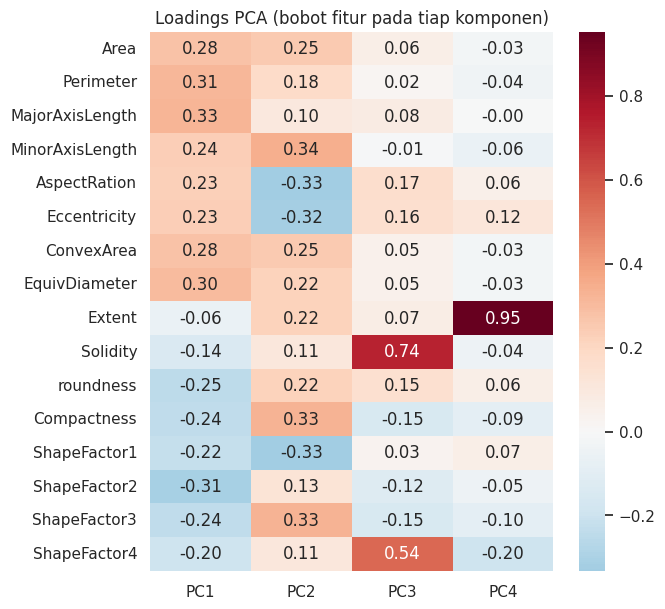

PC1: didominasi oleh ['MajorAxisLength', 'ShapeFactor2', 'Perimeter', 'EquivDiameter']
PC2: didominasi oleh ['MinorAxisLength', 'ShapeFactor1', 'AspectRation', 'Compactness']
PC3: didominasi oleh ['Solidity', 'ShapeFactor4', 'AspectRation', 'Eccentricity']


In [37]:
# Create a DataFrame containing PCA load values for the first 4 principal components, indexed by features
loadings = pd.DataFrame(pca_full.components_[:4].T, index=FITUR,
                        columns=[f"PC{i + 1}" for i in range(4)])
# Initialize a figure and an axis with a custom size of 6.5 x 7 inches for the loadings heatmap
fig, ax = plt.subplots(figsize=(6.5, 7))
# Plot a heatmap of feature loadings using a diverging color palette centered at 0
sns.heatmap(loadings, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax)
# Set the title of the heatmap plot
ax.set_title("Loadings PCA (bobot fitur pada tiap komponen)")
# Save the generated loading plot to the output folder and render it
simpan(fig, "A3_loadings_pca.png")
# Loop through the first 3 columns of the loadings DataFrame to identify top contributing features
for pc in loadings.columns[:3]:
    # Retrieve the top 4 features with the highest absolute loading scores for the current component
    top = loadings[pc].abs().sort_values(ascending=False).head(4).index.tolist()
    # Print the component and its dominant features
    print(f"{pc}: didominasi oleh {top}")

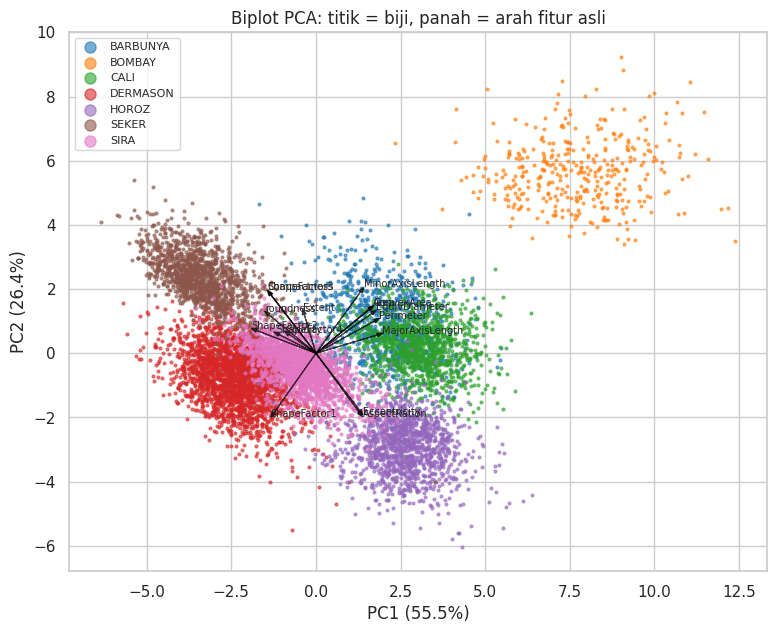

In [38]:
# Fit a PCA model with 2 components on the scaled training features
pca2 = PCA(n_components=2).fit(Z_tr)
# Project the scaled training features into the 2D principal component space
P_tr = pca2.transform(Z_tr)
# Initialize a single plot with a defined custom figure size for the biplot
fig, ax = plt.subplots(figsize=(9, 7))
# Loop through each unique dry bean class to scatter plot its data points
for k in KELAS:
    # Create a boolean mask to identify rows belonging to the current class
    m = (y_tr == k).values
    # Plot scattered points for the current class with small marker sizes and distinct colors
    ax.scatter(P_tr[m, 0], P_tr[m, 1], s=4, color=PALET[k], label=k, alpha=0.6)
# Compute a scaling factor to adjust the length of the feature loading arrows
skala = np.abs(P_tr).max() * 0.45
# Loop through each original feature to draw its loading vector on the biplot
for i, f in enumerate(FITUR):
    # Calculate scaled x and y coordinates for the loading vector arrow
    vx, vy = pca2.components_[0, i] * skala, pca2.components_[1, i] * skala
    # Draw an arrow representing the direction and magnitude of the original feature
    ax.arrow(0, 0, vx, vy, color="black", alpha=0.7, head_width=0.12, lw=0.8)
    # Label the arrow with the feature name near its tip
    ax.text(vx * 1.08, vy * 1.08, f, fontsize=7)
# Set labels for the axes using explained variance ratios, and add a plot title
ax.set(xlabel=f"PC1 ({pca2.explained_variance_ratio_[0] * 100:.1f}%)",
       ylabel=f"PC2 ({pca2.explained_variance_ratio_[1] * 100:.1f}%)",
       title="Biplot PCA: titik = biji, panah = arah fitur asli")
# Add the legend with customized marker scaling and font size
ax.legend(markerscale=4, fontsize=8)
# Save the final PCA biplot figure to the output folder and display it
simpan(fig, "A4_biplot_pca.png")

## A.5 LDA
LDA mencari kombinasi linear fitur yang memaksimalkan rasio
(varians antar-kelas) / (varians dalam-kelas). Dengan 7 kelas,
LDA paling banyak menghasilkan 6 komponen (diskriminan).

Jumlah komponen LDA maksimum: 6
Rasio varians antar-kelas yang dijelaskan tiap LD: [0.541 0.215 0.105 0.092 0.031 0.015]


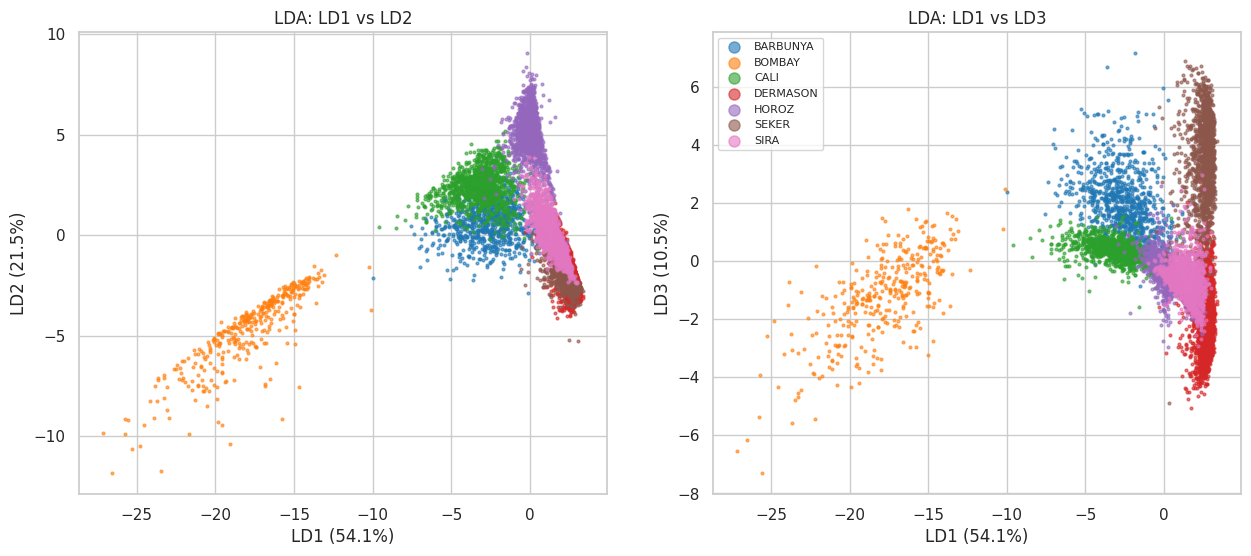

In [39]:
# Fit a Linear Discriminant Analysis (LDA) model on the scaled training features and target labels
lda = LDA().fit(Z_tr, y_tr)
# Print the total number of discriminant components generated by the LDA model
print("Jumlah komponen LDA maksimum:", lda.explained_variance_ratio_.size)
# Print the percentage of between-class variance explained by each discriminant coordinate
print("Rasio varians antar-kelas yang dijelaskan tiap LD:",
      lda.explained_variance_ratio_.round(3))
# Project the scaled training features into the LDA discriminant space
L_tr = lda.transform(Z_tr)

# Initialize a side-by-side plot layout with two subplots for projection visualization
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
# Loop through both subplots to draw scatter plots for two different projection planes
for a, (i, j) in zip(ax, [(0, 1), (0, 2)]):
    # Loop through each unique dry bean class to plot its respective projected points
    for k in KELAS:
        # Create a boolean filter mask for training rows belonging to the current class
        m = (y_tr == k).values
        # Scatter plot the LDA coordinates for this class with custom marker colors and sizes
        a.scatter(L_tr[m, i], L_tr[m, j], s=4, color=PALET[k], label=k, alpha=0.6)
    # Set x and y labels indicating the current discriminant coordinate and variance
    a.set(xlabel=f"LD{i + 1} ({lda.explained_variance_ratio_[i] * 100:.1f}%)",
          ylabel=f"LD{j + 1} ({lda.explained_variance_ratio_[j] * 100:.1f}%)")
# Add a title to the first subplot visualizing LD1 vs LD2
ax[0].set_title("LDA: LD1 vs LD2")
# Add a title to the second subplot visualizing LD1 vs LD3
ax[1].set_title("LDA: LD1 vs LD3")
# Display the class legend inside the second plot with custom dimensions
ax[1].legend(markerscale=4, fontsize=8)
# Save the final dual-panel LDA projection figure to the output folder and show it
simpan(fig, "A5_proyeksi_lda.png")

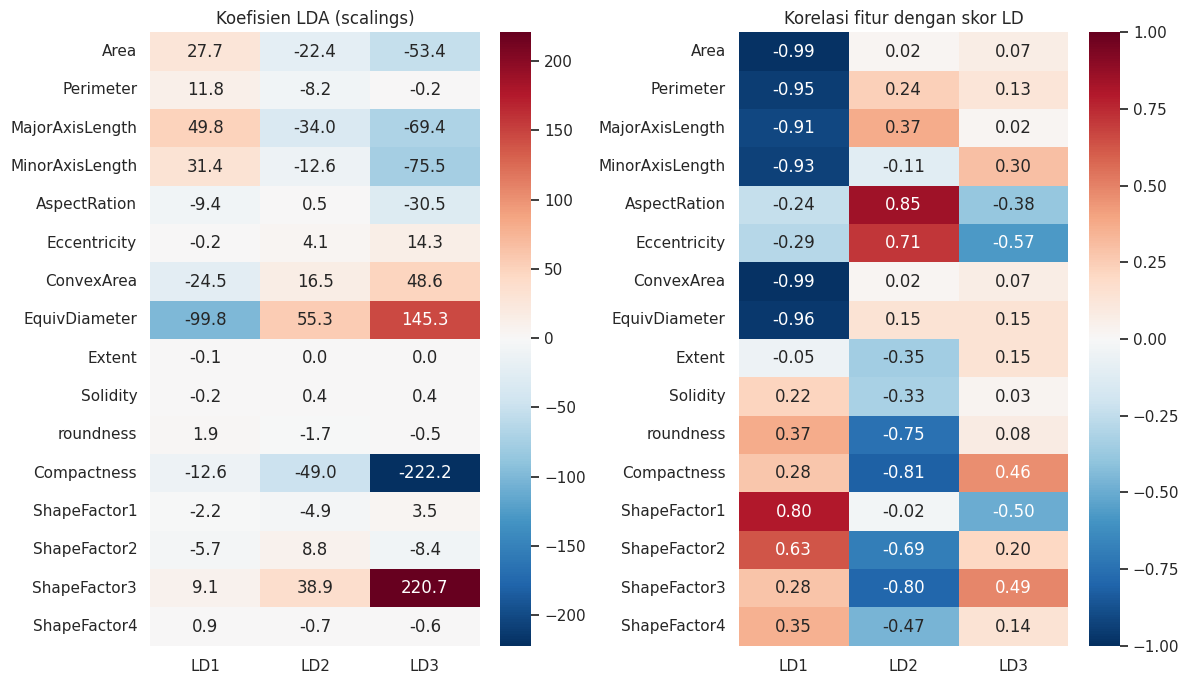

In [40]:
# Koefisien (scalings) LDA: fitur mana yang paling menentukan pemisahan kelas.
# Karena fitur sangat berkorelasi, koefisien bisa besar dan saling meniadakan
# (multikolinearitas). Bandingkan dengan korelasi fitur terhadap skor LD
# (structure coefficients) yang lebih stabil untuk ditafsirkan.
koef = pd.DataFrame(lda.scalings_[:, :3], index=FITUR, columns=["LD1", "LD2", "LD3"])
struktur = pd.DataFrame({f"LD{i + 1}": [np.corrcoef(Z_tr[:, f], L_tr[:, i])[0, 1]
                                        for f in range(len(FITUR))] for i in range(3)},
                        index=FITUR)
fig, ax = plt.subplots(1, 2, figsize=(12, 7))
sns.heatmap(koef, annot=True, fmt=".1f", cmap="RdBu_r", center=0, ax=ax[0])
ax[0].set_title("Koefisien LDA (scalings)")
sns.heatmap(struktur, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax[1])
ax[1].set_title("Korelasi fitur dengan skor LD")
fig.tight_layout()
simpan(fig, "A6_koefisien_lda.png")

## A.6 Perbandingan PCA vs LDA dalam 2 dimensi

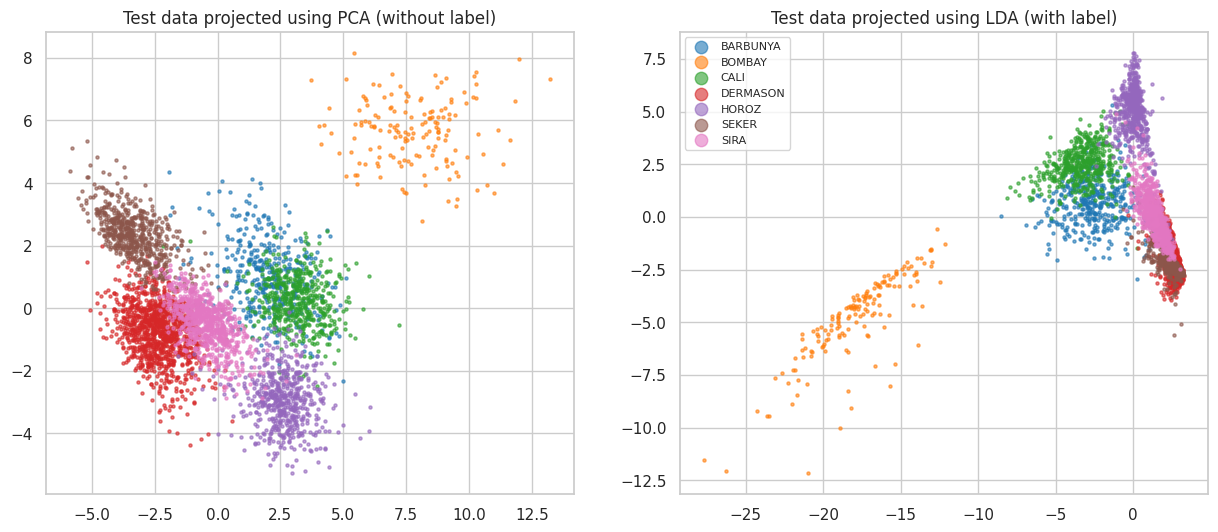

In [41]:
# Project the scaled test features into the 2D principal component space
P_te = pca2.transform(Z_te)
# Fit a Linear Discriminant Analysis model using 2 components on training data
L2 = LDA(n_components=2).fit(Z_tr, y_tr)
# Initialize a dual plot layout with two subplots side-by-side
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
# Loop through each axes and its corresponding 2D projection array and title label
for a, (Q, judul) in zip(ax, [(P_te, "PCA (without label)"), (L2.transform(Z_te), "LDA (with label)")]):
    # Loop through each unique dry bean class to scatter plot its test data points
    for k in KELAS:
        # Create a boolean filtering mask for the test rows matching the current class
        m = (y_te == k).values
        # Scatter plot the 2D projected test points using their assigned class colors and sizes
        a.scatter(Q[m, 0], Q[m, 1], s=5, color=PALET[k], label=k, alpha=0.6)
    # Set a title displaying the classification method used for the projection
    a.set_title(f"Test data projected using {judul}")
# Display the class legend inside the second plot panel with scaled marker sizes
ax[1].legend(markerscale=4, fontsize=8)
# Save the comparative 2D projection figure to the output folder and show it
simpan(fig, "A7_pca_vs_lda_2d.png")

## A.7 Uji kuantitatif: akurasi klasifikasi setelah reduksi dimensi
Reduksi dimensi yang baik mempertahankan informasi yang PENTING untuk tugas.
Kita ukur dengan dua classifier sederhana: KNN (berbasis jarak) dan
Logistic Regression. Pipeline memastikan PCA/LDA hanya dilatih pada data latih.

classifier             KNN (k=15)  LogReg
metode        dimensi                    
LDA           1            0.6291  0.6478
              2            0.8125  0.7480
              3            0.9156  0.9153
              4            0.9161  0.9185
              5            0.9168  0.9207
              6            0.9151  0.9185
PCA           1            0.6077  0.6362
              2            0.8641  0.8696
              3            0.8794  0.8782
              4            0.8870  0.8883
              5            0.9143  0.9178
              6            0.9153  0.9200
Tanpa reduksi 16           0.9175  0.9210


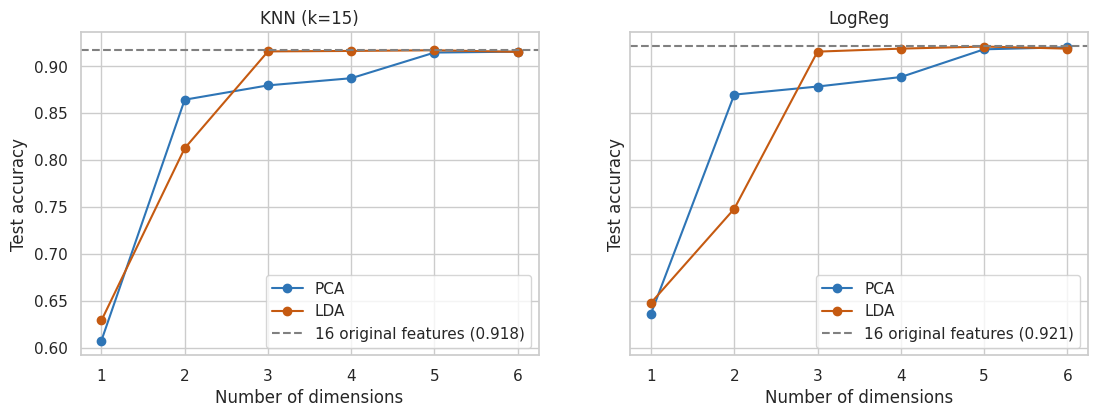

In [42]:
# Helper function to compute test accuracy and execution time of a pipeline
def akurasi(reducer, clf):
    # Construct the pipeline stages: Scaling, optional dimensionality reduction, and the classifier
    langkah = [StandardScaler()] + ([reducer] if reducer is not None else []) + [clf]
    t0 = time.time()  # Record start time of training
    # Instantiate and fit the model pipeline on the training data
    model = make_pipeline(*langkah).fit(X_tr, y_tr)
    # Return the test score (accuracy) and the elapsed execution time
    return model.score(X_te, y_te), time.time() - t0


# List to collect quantitative evaluation results
hasil = []
# Loop over K-Nearest Neighbors and Logistic Regression classifiers
for nama_clf, clf in [("KNN (k=15)", KNeighborsClassifier(15)),
                      ("LogReg", LogisticRegression(max_iter=3000))]:
    # Evaluate the baseline model performance without any dimensionality reduction
    acc, dt = akurasi(None, clf)
    hasil.append({"metode": "Tanpa reduksi", "dimensi": len(FITUR), "classifier": nama_clf,
                  "akurasi": acc, "waktu_dtk": dt})
    # Loop through dimensions from 1 to 6 to evaluate PCA and LDA
    for k in range(1, 7):
        for nama, red in [("PCA", PCA(n_components=k)), ("LDA", LDA(n_components=k))]:
            # Evaluate accuracy and execution time on reduced dimensions
            acc, dt = akurasi(red, clf)
            hasil.append({"metode": nama, "dimensi": k, "classifier": nama_clf,
                          "akurasi": acc, "waktu_dtk": dt})
# Convert compiled evaluation results into a pandas DataFrame
hasil = pd.DataFrame(hasil)
# Reshape results using a pivot table for side-by-side comparison of classifiers
tabel = hasil.pivot_table(index=["metode", "dimensi"], columns="classifier", values="akurasi")
print(tabel.round(4).to_string())
# Save the final accuracy table to a CSV file
tabel.round(4).to_csv(os.path.join(OUT_DIR, "akurasi_pca_vs_lda.csv"))

# Create a side-by-side plot layout comparing accuracies across different dimensions
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for a, c in zip(ax, ["KNN (k=15)", "LogReg"]):
    for nama, warna in [("PCA", "#2e75b6"), ("LDA", "#c55a11")]:
        # Filter accuracy results for the active classifier and dimensionality reduction method
        s = hasil[(hasil.metode == nama) & (hasil.classifier == c)]
        # Plot accuracy trends across different target dimensions
        a.plot(s.dimensi, s.akurasi, "o-", color=warna, label=nama)
    # Fetch baseline accuracy without dimensionality reduction
    base = hasil[(hasil.metode == "Tanpa reduksi") & (hasil.classifier == c)].akurasi.iloc[0]
    # Draw a horizontal line showing baseline classification performance
    a.axhline(base, ls="--", color="grey", label=f"16 original features ({base:.3f})")
    # Customize title and axis labels for clarity
    a.set(title=c, xlabel="Number of dimensions", ylabel="Test accuracy")
    a.legend()
# Save the performance-versus-dimension visualization
simpan(fig, "A8_akurasi_vs_dimensi.png")

A7 B : Removes BOMBAY. bean[bean["Class"] != "BOMBAY"] keeps every row except BOMBAY beans, leaving 6 varieties.
Splits the data again. It makes a new 70:30 train/test split with the same settings as A.1, so the comparison with the earlier results is fair. The scaler, PCA, and LDA are fitted on the training part only, which avoids leakage.
Defines akurasi2. This helper builds a pipeline of scaler, then PCA or LDA (or nothing), then the classifier. It trains the pipeline on the training data and returns the accuracy on the test data.
Loops over the settings. For both classifiers (KNN and logistic regression), it first records the baseline with all 16 features. It then tests PCA and LDA with 1 to 5 components. The limit is 5 because LDA can produce at most (number of classes − 1) components, and 6 classes remain.
Prints a table. The pivot table lists accuracy by method and number of dimensions, with one column per classifier. It has the same layout as your A.7 table, so you can compare the two directly.

In [43]:
# A.6 — tanpa BOMBAY
bean2 = bean[bean["Class"] != "BOMBAY"].reset_index(drop=True)
X2, y2 = bean2[FITUR], bean2["Class"]
X_tr2, X_te2, y_tr2, y_te2 = train_test_split(X2, y2, test_size=0.3,
                                              stratify=y2, random_state=RANDOM_STATE)

def akurasi2(reducer, clf):
    langkah = [StandardScaler()] + ([reducer] if reducer is not None else []) + [clf]
    return make_pipeline(*langkah).fit(X_tr2, y_tr2).score(X_te2, y_te2)

baris = []
for nm, clf in [("KNN (k=15)", KNeighborsClassifier(15)),
                ("LogReg", LogisticRegression(max_iter=3000))]:
    baris.append({"metode": "Tanpa reduksi", "dimensi": 16,
                  "classifier": nm, "akurasi": akurasi2(None, clf)})
    for k in range(1, 6):          # 6 kelas tersisa -> LDA maks 5 komponen
        for mn, red in [("PCA", PCA(n_components=k)), ("LDA", LDA(n_components=k))]:
            baris.append({"metode": mn, "dimensi": k,
                          "classifier": nm, "akurasi": akurasi2(red, clf)})

t2 = pd.DataFrame(baris).pivot_table(index=["metode", "dimensi"],
                                     columns="classifier", values="akurasi")
print(t2.round(4).to_string())

classifier             KNN (k=15)  LogReg
metode        dimensi                    
LDA           1            0.5974  0.6240
              2            0.9015  0.9063
              3            0.9066  0.9117
              4            0.9143  0.9171
              5            0.9158  0.9176
PCA           1            0.5887  0.6138
              2            0.8677  0.8741
              3            0.8782  0.8769
              4            0.8897  0.8892
              5            0.9189  0.9199
Tanpa reduksi 16           0.9194  0.9196


In [44]:
# Create and fit a pipeline that standardizes features and fits a Linear Discriminant Analysis classifier
lda_clf = make_pipeline(StandardScaler(), LDA()).fit(X_tr, y_tr)
# Evaluate and print the classifier's overall accuracy score on the test set
print(f"Akurasi LDA sebagai classifier: {lda_clf.score(X_te, y_te):.4f}")
# Generate and print a comprehensive metrics report (precision, recall, f1-score) for all classes
print(classification_report(y_te, lda_clf.predict(X_te), digits=3))

Akurasi LDA sebagai classifier: 0.9035
              precision    recall  f1-score   support

    BARBUNYA      0.959     0.829     0.889       397
      BOMBAY      1.000     1.000     1.000       156
        CALI      0.897     0.961     0.928       489
    DERMASON      0.953     0.843     0.895      1064
       HOROZ      0.970     0.916     0.942       558
       SEKER      0.956     0.926     0.941       608
        SIRA      0.758     0.942     0.840       791

    accuracy                          0.904      4063
   macro avg      0.928     0.917     0.919      4063
weighted avg      0.913     0.904     0.905      4063



## A.8 Kaitan dengan clustering (praktikum sebelumnya)
Apakah K-Means lebih baik bila dijalankan di ruang PCA atau LDA?
PERHATIAN: ruang LDA dibentuk MEMAKAI LABEL. Clustering di ruang LDA lalu
dibandingkan dengan label yang sama adalah "kebocoran label" (label leakage).
Apa pun hasilnya, perbandingan ini tidak jujur sebagai unsupervised learning.
Amati: apakah memakai label otomatis membuat K-Means lebih baik?

In [45]:
# Standardize all original features to zero mean and unit variance
Z_all = StandardScaler().fit_transform(X_all)
# Initialize a dictionary mapping space names to their respective feature arrays, starting with the original scaled features
ruang = {"16 features (original)": Z_all}
# Loop through 2, 4, and 6 components to generate and store PCA-reduced representations
for k in (2, 4, 6):
    ruang[f"PCA {k} components"] = PCA(n_components=k).fit_transform(Z_all)
# Loop through 2 and 6 components to generate and store LDA-reduced representations (note: uses target labels)
for k in (2, 6):
    ruang[f"LDA {k} components (labeled!)"] = LDA(n_components=k).fit_transform(Z_all, y_all)
# Compute the Adjusted Rand Index (ARI) comparing K-Means clustering (7 clusters) against the true labels for each representation
ari = {n: adjusted_rand_score(y_all, KMeans(7, n_init=10, random_state=RANDOM_STATE).fit_predict(Q))
       for n, Q in ruang.items()}
# Convert ARI results into a pandas Series, round values to 3 decimal places, and print them
print(pd.Series(ari, name="ARI K-Means vs label").round(3).to_string())

16 features (original)         0.667
PCA 2 components               0.687
PCA 4 components               0.659
PCA 6 components               0.667
LDA 2 components (labeled!)    0.521
LDA 6 components (labeled!)    0.701


---
# BAGIAN B — Kartu Kredit (tanpa label)
## B.1 PCA untuk memahami struktur perilaku nasabah

Kartu kredit — komponen untuk 90% varians: 8


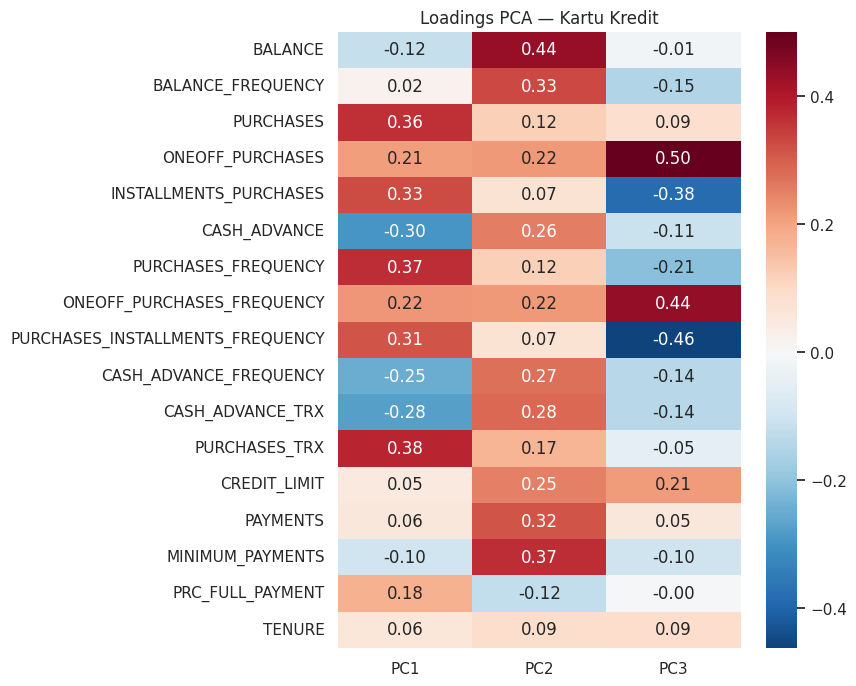

In [46]:
# Load the credit card dataset and drop the unique customer identifier column
kr = pd.read_csv("dataset_kartu_kredit.csv").drop(columns="CUST_ID")
# Drop rows where the critical CREDIT_LIMIT feature has missing values and reset index
kr = kr.dropna(subset=["CREDIT_LIMIT"]).reset_index(drop=True)
# Impute missing MINIMUM_PAYMENTS values with their corresponding feature median
kr["MINIMUM_PAYMENTS"] = kr["MINIMUM_PAYMENTS"].fillna(kr["MINIMUM_PAYMENTS"].median())
# Cap the CASH_ADVANCE_FREQUENCY feature at a maximum value of 1 to handle outliers
kr["CASH_ADVANCE_FREQUENCY"] = kr["CASH_ADVANCE_FREQUENCY"].clip(upper=1)
# Define highly skewed numeric features that require log transformation
LOG = ["BALANCE", "PURCHASES", "ONEOFF_PURCHASES", "INSTALLMENTS_PURCHASES", "CASH_ADVANCE",
       "CASH_ADVANCE_TRX", "PURCHASES_TRX", "CREDIT_LIMIT", "PAYMENTS", "MINIMUM_PAYMENTS"]
# Compile a clean list of all remaining active feature column names
K_FITUR = list(kr.columns)
# Create a copy of the cleaned dataset to preserve original values before scaling
Xk = kr.copy()
# Apply log-transform to highly skewed features using log1p to safely handle zeros
Xk[LOG] = np.log1p(Xk[LOG])
# Standardize all transformed features to zero mean and unit variance
Zk = StandardScaler().fit_transform(Xk)

# Instantiate and fit a full Principal Component Analysis model on the standardized data
pk = PCA().fit(Zk)
# Compute the cumulative sum of explained variance ratios across all components
kum_k = np.cumsum(pk.explained_variance_ratio_)
# Identify and print the number of components needed to retain at least 90% total variance
print("Kartu kredit — komponen untuk 90% varians:", int(np.argmax(kum_k >= 0.9) + 1))

# Create a loading DataFrame containing feature weights for the first 3 principal components
load_k = pd.DataFrame(pk.components_[:3].T, index=K_FITUR, columns=["PC1", "PC2", "PC3"])
# Set up a single heatmap plot with custom dimension proportions for readability
fig, ax = plt.subplots(figsize=(6.5, 8))
# Plot a seaborn heatmap showing feature loadings using a centered diverging colormap
sns.heatmap(load_k, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax)
# Define the title of the credit card PCA loading heatmap
ax.set_title("Loadings PCA — Kartu Kredit")
# Save the final loading plot figure to the designated output folder and render it
simpan(fig, "B1_loadings_kredit.png")

## B.2 LDA tidak bisa langsung dipakai... kecuali kita punya label
Trik yang umum dipakai: jalankan K-Means, lalu gunakan label klaster sebagai
target LDA. LDA kemudian menunjukkan fitur mana yang paling membedakan segmen.
Ini alat untuk MENJELASKAN klaster, bukan untuk menemukan klaster baru.

Rasio pemisahan tiap LD: [0.653 0.347]


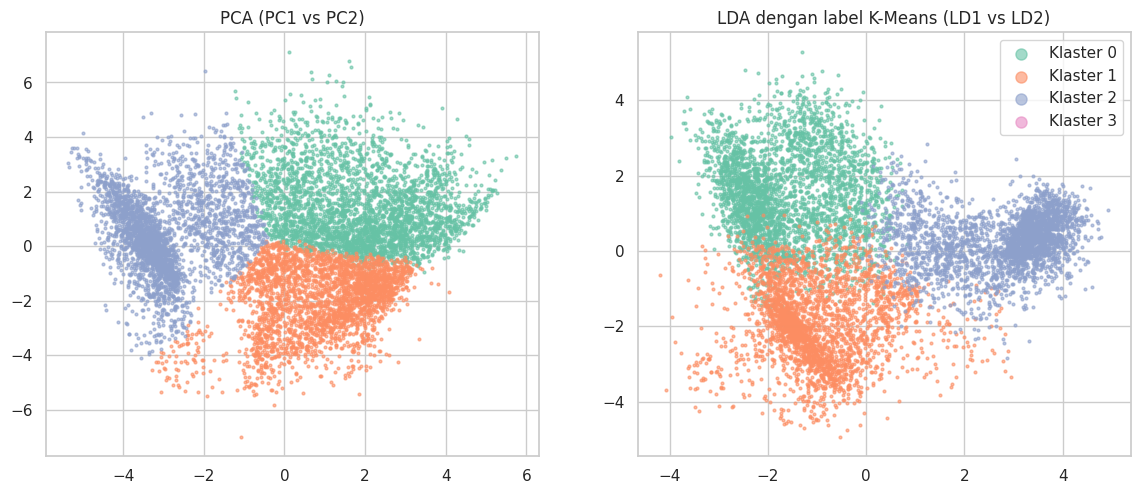


Fitur paling berkaitan dengan LD1 (pembeda segmen utama):
PURCHASES                          -0.893
PURCHASES_TRX                      -0.878
PURCHASES_FREQUENCY                -0.849
INSTALLMENTS_PURCHASES             -0.754
CASH_ADVANCE                        0.728
PURCHASES_INSTALLMENTS_FREQUENCY   -0.683

Median fitur per klaster (skala asli):
         PURCHASES  CASH_ADVANCE  INSTALLMENTS_PURCHASES  PURCHASES_FREQUENCY  \
Klaster                                                                         
0           1449.1           0.0                   491.4                  0.9   
1            308.2           0.0                   158.0                  0.5   
2              0.0        1364.0                     0.0                  0.0   

         BALANCE  
Klaster           
0         1273.8  
1           56.7  
2         1616.0  

Selesai. Gambar dan tabel tersimpan di folder output_pca_lda/


In [47]:
# Run K-Means clustering to partition the standardized data into 4 distinct customer segments
lab_km = KMeans(3, n_init=10, random_state=RANDOM_STATE).fit_predict(Zk)
# Fit a Linear Discriminant Analysis model using the generated K-Means cluster labels as targets
lda_k = LDA().fit(Zk, lab_km)
# Project the standardized features into the fitted LDA discriminant space
Lk = lda_k.transform(Zk)
# Keep only the first 2 principal components of the PCA-projected space for visual comparison
Pk = pk.transform(Zk)[:, :2]
# Print the percentage of variance explained by each generated discriminant component
print("Rasio pemisahan tiap LD:", lda_k.explained_variance_ratio_.round(3))

# Initialize a dual plot layout with two subplots side-by-side
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
# Define a colorful 4-color palette to represent the four customer clusters
pal4 = sns.color_palette("Set2", 4)
# Loop through each subplot to scatter-plot PCA projections and LDA projections
for a, (Q, judul) in zip(ax, [(Pk, "PCA (PC1 vs PC2)"), (Lk, "LDA dengan label K-Means (LD1 vs LD2)")]):
    # Loop through each cluster label (0 to 3) to render segment data points
    for c in range(4):
        # Create a boolean filter mask for rows belonging to the current cluster
        m = lab_km == c
        # Scatter plot data points belonging to the current cluster using its distinct color
        a.scatter(Q[m, 0], Q[m, 1], s=4, color=pal4[c], label=f"Klaster {c}", alpha=0.6)
    # Set title for the current subplot
    a.set_title(judul)
# Add a legend inside the second subplot panel with scaled marker sizes
ax[1].legend(markerscale=4)
# Save the final dual comparison figure to the output folder and show it
simpan(fig, "B2_kredit_pca_vs_lda.png")

# Compute correlation coefficients between all original features and the first discriminant coordinate
struk_k = pd.Series([np.corrcoef(Zk[:, f], Lk[:, 0])[0, 1] for f in range(len(K_FITUR))],
                    index=K_FITUR, name="korelasi dengan LD1")
# Print heading for features most correlated with the first discriminant coordinate
print("\nFitur paling berkaitan dengan LD1 (pembeda segmen utama):")
# Sort features by absolute correlation values in descending order and display the top 6
print(struk_k.reindex(struk_k.abs().sort_values(ascending=False).index).head(6).round(3).to_string())
# Print heading for the physical median statistics computed across segments
print("\nMedian fitur per klaster (skala asli):")
# Assign cluster labels to the original dataset and print key feature medians per segment
print(kr.assign(Klaster=lab_km).groupby("Klaster")[["PURCHASES", "CASH_ADVANCE",
      "INSTALLMENTS_PURCHASES", "PURCHASES_FREQUENCY", "BALANCE"]].median().round(1))
# Output a final confirmation message detailing where files and visualizations were saved
print(f"\nSelesai. Gambar dan tabel tersimpan di folder {OUT_DIR}/")

cc

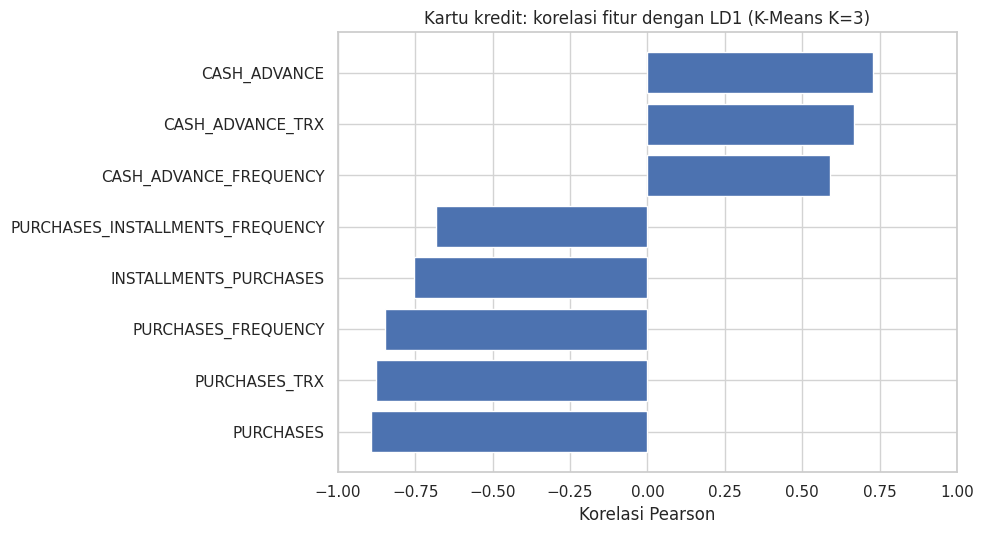

In [48]:

# Select the credit-card features shown in the reference chart
fitur_pilihan = [
    "CASH_ADVANCE",
    "CASH_ADVANCE_TRX",
    "CASH_ADVANCE_FREQUENCY",
    "PURCHASES_INSTALLMENTS_FREQUENCY",
    "INSTALLMENTS_PURCHASES",
    "PURCHASES_FREQUENCY",
    "PURCHASES_TRX",
    "PURCHASES"
]

# Get the correlation values calculated by the existing notebook
korelasi = struk_k.reindex(fitur_pilihan).dropna()

# Create the horizontal bar chart
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.barh(korelasi.index, korelasi.values, color="#4C72B0")

# Add the chart title and axis label
ax.set_title("Kartu kredit: korelasi fitur dengan LD1 (K-Means K=3)")
ax.set_xlabel("Korelasi Pearson")

# Set the axis range and display grid lines
ax.set_xlim(-1, 1)
ax.grid(axis="both", color="lightgray")
ax.set_axisbelow(True)

# Place CASH_ADVANCE at the top
ax.invert_yaxis()

# Adjust the layout and save the chart in your output folder
plt.tight_layout()
simpan(fig, "B3_korelasi_fitur_LD1_kredit.png")


b3 changing amount of clusters

In [49]:
for K in (3, 4, 5):
    lab = KMeans(K, n_init=10, random_state=RANDOM_STATE).fit_predict(Zk)
    l = LDA().fit(Zk, lab)
    Lk_ = l.transform(Zk)
    s = pd.Series([np.corrcoef(Zk[:, f], Lk_[:, 0])[0, 1] for f in range(len(K_FITUR))], index=K_FITUR)
    print(f"\n=== K = {K} | rasio LD:", l.explained_variance_ratio_.round(3))
    print(s.reindex(s.abs().sort_values(ascending=False).index).head(6).round(3).to_string())
    print(kr.assign(Klaster=lab).groupby("Klaster")[["PURCHASES","CASH_ADVANCE",
          "INSTALLMENTS_PURCHASES","PURCHASES_FREQUENCY","BALANCE"]].median().round(1))



=== K = 3 | rasio LD: [0.653 0.347]
PURCHASES                          -0.893
PURCHASES_TRX                      -0.878
PURCHASES_FREQUENCY                -0.849
INSTALLMENTS_PURCHASES             -0.754
CASH_ADVANCE                        0.728
PURCHASES_INSTALLMENTS_FREQUENCY   -0.683
         PURCHASES  CASH_ADVANCE  INSTALLMENTS_PURCHASES  PURCHASES_FREQUENCY  \
Klaster                                                                         
0           1449.1           0.0                   491.4                  0.9   
1            308.2           0.0                   158.0                  0.5   
2              0.0        1364.0                     0.0                  0.0   

         BALANCE  
Klaster           
0         1273.8  
1           56.7  
2         1616.0  

=== K = 4 | rasio LD: [0.527 0.303 0.171]
PURCHASES_FREQUENCY                 0.947
PURCHASES_TRX                       0.928
PURCHASES                           0.870
INSTALLMENTS_PURCHASES              0.823